Task 1: Use Linear Regression to predict Q from the variables n, P, ∆p, and any combinations
thereof that you find relevant. Use the dataset train1.csv as your training data, and test1.csv
as your test data. Report your test error and the parameters of your best-performing regression model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Load the data through the shared loader in src/data.py,
# so every notebook uses the same train (train1.csv) and test (test1.csv) files.
import sys
sys.path.append("..")
from src.data import load_case1, add_features

train_data, test_data = load_case1()

# Check: training data should be (480, 8) and test data (120, 8).
print("Training data:", train_data.shape)
print("Test data:", test_data.shape)
print(train_data.head())
print("Missing values in training data:\n", train_data.isna().sum())

Training data: (480, 8)
Test data: (120, 8)
             pump_id  elapsed_s operating_state    speed_rpm     power_w  \
0  99223468_model_01       14.5          stable  4230.396017  669.992714   
1  99223468_model_01       24.5          stable  3796.519900  931.528480   
2  99223468_model_01       34.5          stable  3508.264375  724.198083   
3  99223468_model_01       44.5          stable  1498.405243   99.463217   
4  99223468_model_01       64.5          stable  3224.873653  608.195308   

   inlet_pressure_bar  outlet_pressure_bar  flow_m3_h  
0            1.057136             2.414427   0.652884  
1            2.097392             2.390436  43.040564  
2            2.247896             2.433662  40.939560  
3            2.287246             2.451128  11.857951  
4            2.464618             2.696299  36.000996  
Missing values in training data:
 pump_id                0
elapsed_s              0
operating_state        0
speed_rpm              0
power_w                0
inle

In [3]:
# add_features (src/data.py) converts speed to thousands of RPM, power to kW,
# and calculates the pressure increase across the pump (outlet - inlet).
train_data = add_features(train_data)
test_data = add_features(test_data)

feature_names = ["speed_krpm", "power_kw", "pressure_difference_bar"]
target_name = "flow_m3_h"

X_train = train_data[feature_names]
y_train = train_data[target_name]
X_test = test_data[feature_names]
y_test = test_data[target_name]

print(X_train.head())

   speed_krpm  power_kw  pressure_difference_bar
0    4.230396  0.669993                 1.357291
1    3.796520  0.931528                 0.293043
2    3.508264  0.724198                 0.185766
3    1.498405  0.099463                 0.163881
4    3.224874  0.608195                 0.231682


In [4]:
# Compare 7 versions of linear regression, using only the training data.
# All of them try to predict water flow from pump speed, pump power and pressure difference.
# The degree means how many times we can multiply input features together in one term.
# Degree 1: n, P, delta_p
# Degree 2: also squares and pairwise products
# Degree 3: also cubic combinations, and so on.
# We go up to degree 7 so we can see where the cross-validation error stops improving
# and starts getting worse again (overfitting). If the best degree were the largest one
# we tried, a higher one might be even better.
cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for degree in [1, 2, 3, 4, 5, 6, 7]:
    candidate_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    fold_rmse = -cross_val_score(
        candidate_model, X_train, y_train,
        cv=cross_validation,
        scoring="neg_root_mean_squared_error"
    )
    results.append({"degree": degree, "mean_cv_rmse": fold_rmse.mean(),
                    "std_cv_rmse": fold_rmse.std()})

cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))

best_degree = int(cv_results.loc[cv_results["mean_cv_rmse"].idxmin(), "degree"])
print("\nChosen polynomial degree:", best_degree)

 degree  mean_cv_rmse  std_cv_rmse
      1      3.480021     0.160257
      2      1.234753     0.066603
      3      0.871082     0.043473
      4      0.797330     0.039504
      5      0.748089     0.068183
      6      0.807746     0.111742
      7      1.734839     1.032220

Chosen polynomial degree: 5


We used 5-fold cross-validation to perform model selection, progressively increasing the polynomial degree and selecting the model with the lowest average validation RMSE.

**Important distinction:** increasing complexity is the model-building strategy. Cross-validation is the evaluation method used to choose between the models.

In [5]:
# After choosing the model with cross-validation, we train it on ALL the training observations.
best_model = make_pipeline(
    PolynomialFeatures(degree=best_degree, include_bias=False),
    LinearRegression()
)
best_model.fit(X_train, y_train)

# Evaluate the test set only after selecting the model.
predicted_flow = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predicted_flow)
rmse = np.sqrt(mean_squared_error(y_test, predicted_flow))
r2 = r2_score(y_test, predicted_flow)

print(f"Test MAE:  {mae:.4f} m³/h")
print(f"Test RMSE: {rmse:.4f} m³/h")
print(f"Test R²:   {r2:.4f}")

Test MAE:  0.5260 m³/h
Test RMSE: 0.6788 m³/h
Test R²:   0.9968


In [6]:

# Predictions on training and test data
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

# Calculate errors
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("Training RMSE:", round(train_rmse, 4))
print("Test RMSE:", round(test_rmse, 4))


Training RMSE: 0.6355
Test RMSE: 0.6788


In [7]:
# Print the fitted intercept and every coefficient.
polynomial_step = best_model.named_steps["polynomialfeatures"]
regression_step = best_model.named_steps["linearregression"]

expanded_feature_names = polynomial_step.get_feature_names_out(feature_names)

print("Intercept:", regression_step.intercept_)
print("\nRegression coefficients:")
for feature, coefficient in zip(expanded_feature_names, regression_step.coef_):
    print(f"{feature:55s} {coefficient: .6f}")

# Coefficients correspond to n in krpm, P in kW, and delta_p in bar.

Intercept: 966.79090067381

Regression coefficients:
speed_krpm                                              -2606.252674
power_kw                                                 2545.187638
pressure_difference_bar                                  2437.914045
speed_krpm^2                                             2793.570912
speed_krpm power_kw                                     -3723.949097
speed_krpm pressure_difference_bar                      -5805.270110
power_kw^2                                               1234.210827
power_kw pressure_difference_bar                         1011.198206
pressure_difference_bar^2                                5772.033833
speed_krpm^3                                            -1506.270752
speed_krpm^2 power_kw                                    2405.494762
speed_krpm^2 pressure_difference_bar                     4697.139168
speed_krpm power_kw^2                                   -1749.293778
speed_krpm power_kw pressure_difference_bar       

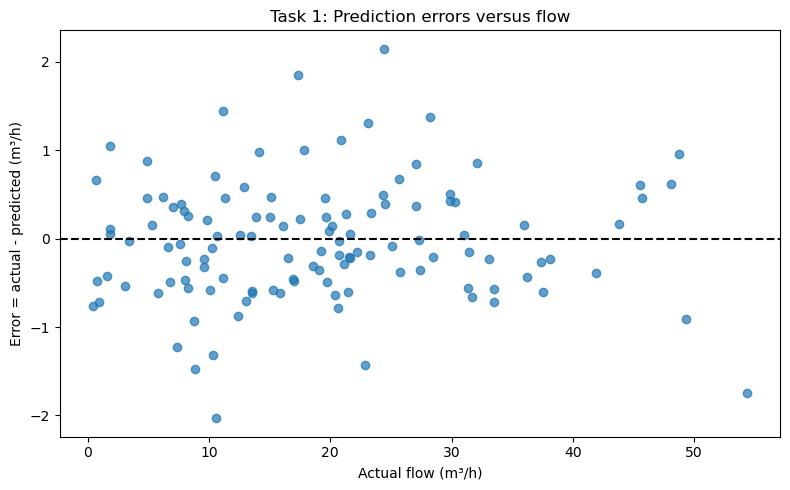

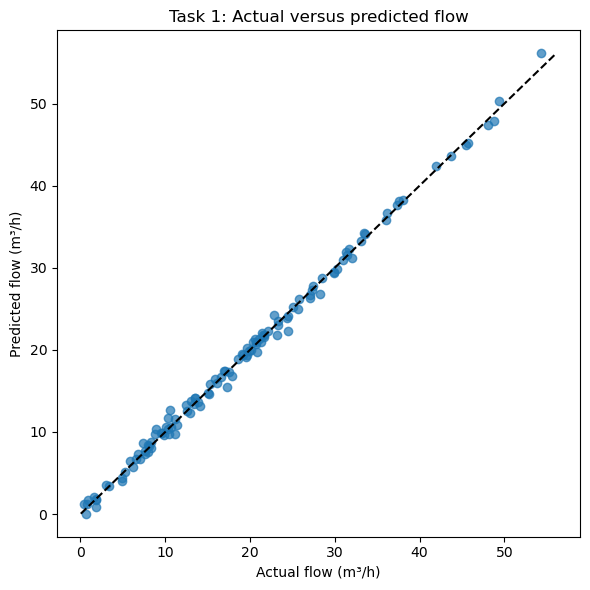

In [8]:
# Plot errors versus true flow rate (saved to report/figures/ for the report).
errors = y_test.to_numpy() - predicted_flow
plt.figure(figsize=(8, 5))
plt.scatter(y_test, errors, alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Actual flow (m³/h)")
plt.ylabel("Error = actual - predicted (m³/h)")
plt.title("Task 1: Prediction errors versus flow")
plt.tight_layout()
plt.savefig("../report/figures/task1_error_vs_flow.png", dpi=200, bbox_inches="tight")
plt.show()

# Actual versus predicted values.
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predicted_flow, alpha=0.7)
limits = [min(y_test.min(), predicted_flow.min()), max(y_test.max(), predicted_flow.max())]
plt.plot(limits, limits, "k--")
plt.xlabel("Actual flow (m³/h)")
plt.ylabel("Predicted flow (m³/h)")
plt.title("Task 1: Actual versus predicted flow")
plt.tight_layout()
plt.savefig("../report/figures/task1_actual_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusion (Task 1)

**Model selection.** We fitted polynomial linear regressions of degree 1–7 on the features n (krpm), P (kW) and Δp (bar), and compared them with 5-fold cross-validation on the training data only (train1.csv, 480 rows). The CV RMSE decreases up to **degree 5** (0.748 m³/h) and then increases again (degree 6: 0.808, degree 7: 1.735), which shows overfitting for higher degrees. We therefore chose **degree 5**. Degree 4 (0.797 m³/h) is almost as good, and the difference is about one standard deviation of the CV folds.

**Test error.** After choosing the model, we refitted it on all the training data and evaluated it **once** on the test set (test1.csv, 120 rows):

| Metric | Value |
|---|---|
| Test MAE | 0.526 m³/h |
| Test RMSE | 0.679 m³/h |
| Test R² | 0.997 |
| Training RMSE | 0.636 m³/h |

The training RMSE and test RMSE are close (0.64 vs 0.68), so the final model does not overfit.

**Parameters.** The intercept and all 55 coefficients are printed in the coefficient cell above. They correspond to n in krpm, P in kW and Δp in bar. The coefficients are large and have alternating signs, because the polynomial terms are strongly correlated with each other. They should therefore not be interpreted one by one; only the model as a whole is meaningful.

**Error vs flow.** The errors are spread evenly around 0 (roughly ±2 m³/h) over the whole flow range, without a trend, so the model is not systematically wrong at low or high flow. In relative terms, however, the error matters most at low flow: an error of 0.7 m³/h is small at 40 m³/h but large at 1 m³/h.